In [2]:
# Cell 1: Imports, reproducibility and dataset path settings
# Copy-paste this whole cell as-is into your notebook as the first cell for the LSTM workflow.

import os
from pathlib import Path
import random
import warnings
warnings.filterwarnings("ignore")

# Numerical & data handling
import numpy as np
import pandas as pd

# Visualization (lightweight here)
import matplotlib.pyplot as plt

# Scikit-learn utilities for preprocessing and metrics
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# TensorFlow / Keras for LSTM
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Reproducibility: set seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Dataset path (adapt if your data is in a different folder)
# Primary expected path from your project context; if not found, it'll fallback to listing current dir
DEFAULT_DATA_DIR = Path(r"C:\Users\Riya\Documents\heritage-predictor\env\Data")
if not DEFAULT_DATA_DIR.exists():
    DEFAULT_DATA_DIR = Path("/mnt/data/heritage-predictor/env/Data")  # common container path
if not DEFAULT_DATA_DIR.exists():
    DEFAULT_DATA_DIR = Path.cwd()

# Show a quick summary of environment and available CSV files
print("Python:", os.sys.version.splitlines()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Using data directory:", DEFAULT_DATA_DIR)

csv_files = sorted([p for p in DEFAULT_DATA_DIR.glob("*.csv")])
print(f"Found {len(csv_files)} CSV files:")
for p in csv_files[:20]:
    print("  -", p.name)

# Expose some names for subsequent cells
DATA_DIR = DEFAULT_DATA_DIR
RANDOM_STATE = SEED

# Quick helper function (used later) to load a single CSV and parse datetime
def load_csv(filepath, datetime_col='Datetime', dayfirst=True):
    df = pd.read_csv(filepath, parse_dates=[datetime_col], dayfirst=dayfirst)
    df = df.sort_values(datetime_col).reset_index(drop=True)
    return df

print("\nCell 1 executed: imports and dataset path ready.")


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy: 2.1.3
Pandas: 2.3.0
TensorFlow: 2.19.0
Using data directory: C:\Users\Riya\Documents\heritage-predictor\env\Data
Found 19 CSV files:
  - Barcelona.csv
  - Barcelona02.csv
  - Barcelona03.csv
  - Bath.csv
  - Bath02.csv
  - Bath03.csv
  - Dubai.csv
  - Dubai02.csv
  - Dubai03.csv
  - Edinburgh.csv
  - Gatwick.csv
  - Gatwick02.csv
  - Gatwick03.csv
  - Norway.csv
  - Norway02.csv
  - Norway03.csv
  - Singapore.csv
  - Singapore02.csv
  - Singapore03.csv

Cell 1 executed: imports and dataset path ready.


In [4]:
# Cell 2: Load & prepare datasets for LSTM (fixed datetime parsing)

# --- Parameters ---
datetime_col = "Datetime"
target_cols = ["Indoor_Temp", "Indoor_Humidity"]
lag_hours = 12  # how many past hours to include as features
rolling_hours = [3, 6]  # rolling stats windows
dayfirst_format = True

# --- Load synthetic data (everything except Bath.csv) ---
train_dfs = []
for file in csv_files:
    if file.name.lower().startswith("bath.csv"):
        continue
    df = load_csv(file, datetime_col=datetime_col, dayfirst=dayfirst_format)
    df["source_file"] = file.name
    train_dfs.append(df)

train_df = pd.concat(train_dfs, ignore_index=True)

# --- Load real Bath data for testing ---
test_df = load_csv(DATA_DIR / "Bath.csv", datetime_col=datetime_col, dayfirst=dayfirst_format)

# --- Feature engineering ---
def add_time_features(df):
    # Force datetime type
    df[datetime_col] = pd.to_datetime(df[datetime_col], errors="coerce", dayfirst=True)
    df = df.dropna(subset=[datetime_col])
    df["hour"] = df[datetime_col].dt.hour
    df["month"] = df[datetime_col].dt.month
    df["dayofweek"] = df[datetime_col].dt.dayofweek
    # cyclical encodings
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    return df

def add_lag_features(df, cols, lags):
    for col in cols:
        for lag in range(1, lags+1):
            df[f"{col}_lag{lag}"] = df[col].shift(lag)
    return df

def add_rolling_features(df, cols, windows):
    for col in cols:
        for w in windows:
            df[f"{col}_rollmean{w}"] = df[col].rolling(window=w).mean()
            df[f"{col}_rollstd{w}"] = df[col].rolling(window=w).std()
    return df

def prepare_features(df):
    df = add_time_features(df)
    df = add_lag_features(df, target_cols, lag_hours)
    df = add_rolling_features(df, target_cols, rolling_hours)
    df = df.dropna().reset_index(drop=True)
    return df

train_df = prepare_features(train_df)
test_df = prepare_features(test_df)

# --- Feature/target split ---
feature_cols = [c for c in train_df.columns if c not in [datetime_col] + target_cols + ["source_file"]]
X_train = train_df[feature_cols].values
y_train = train_df[target_cols].values
X_test = test_df[feature_cols].values
y_test = test_df[target_cols].values

print("Train shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)
print("Number of features:", len(feature_cols))


Train shapes: (148896, 41) (148896, 2)
Test shapes: (5306, 41) (5306, 2)
Number of features: 41


In [5]:
# Cell 3: Reshape data for LSTM input

# LSTM expects shape: (samples, timesteps, features_per_timestep)
# We'll use timesteps = 1 here since lag features are already explicit columns
# If you wanted to model sequential dependencies differently, we could instead stack timesteps > 1

timesteps = 1
n_features = X_train.shape[1]

X_train_lstm = X_train.reshape((X_train.shape[0], timesteps, n_features))
X_test_lstm = X_test.reshape((X_test.shape[0], timesteps, n_features))

print("LSTM train shape:", X_train_lstm.shape)
print("LSTM test shape:", X_test_lstm.shape)


LSTM train shape: (148896, 1, 41)
LSTM test shape: (5306, 1, 41)


In [6]:
# Cell 4: Build and compile the LSTM model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Define model
model = Sequential()
model.add(LSTM(64, activation='tanh', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]), return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(32, activation='tanh'))
model.add(Dropout(0.2))
model.add(Dense(2))  # two outputs: Indoor_Temp and Indoor_Humidity

# Compile model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 64)          │        27,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,618 (154.76 KB)

 Trainable params: 39,618 (154.76 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Cell 5: Train the LSTM model

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_lstm_model.keras', monitor='val_loss', save_best_only=True)

# Train
history = model.fit(
    X_train_lstm, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, checkpoint],
    verbose=1
)


Epoch 1/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 720.8778 - mae: 20.3138 - val_loss: 597.6475 - val_mae: 20.0474
Epoch 2/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 182.4666 - mae: 9.9861 - val_loss: 225.9270 - val_mae: 13.1807
Epoch 3/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 90.2863 - mae: 7.0917 - val_loss: 166.7952 - val_mae: 11.1051
Epoch 4/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 57.5133 - mae: 5.6667 - val_loss: 124.8408 - val_mae: 9.2425
Epoch 5/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 48.5752 - mae: 5.2110 - val_loss: 109.8176 - val_mae: 8.8042
Epoch 6/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 43.5067 - mae: 4.9309 - val_loss: 118.6685 - val_mae: 9.1166
Epoch 7/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 40.9162 - mae: 4.7678 - val_loss: 95.4436 - val_mae: 8.1768
Epoch 8/50
1862/1862 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 38.0386 - mae: 4.5922 - val_loss: 98.5066 - val_mae: 8.2243
Epoch 9/50


166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Metrics for Indoor_Temp:
  RMSE: 1.420
  MAE: 1.220
  R2: 0.593

Metrics for Indoor_Humidity:
  RMSE: 2.663
  MAE: 2.103
  R2: 0.801



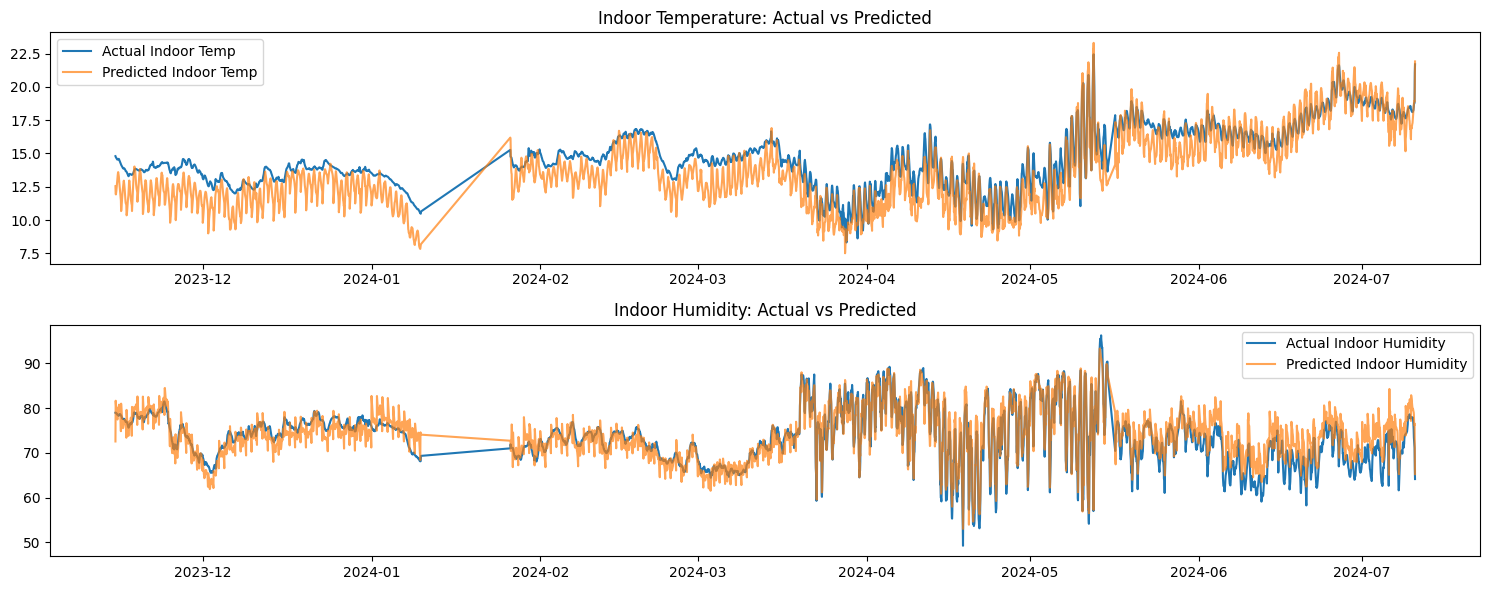

In [8]:
# Cell 6: Load best model, predict, evaluate and visualize

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load best weights from checkpoint
model.load_weights('best_lstm_model.keras')

# Predict on test set
y_pred = model.predict(X_test_lstm)

# Calculate metrics for each target
for i, target in enumerate(target_cols):
    rmse = np.sqrt(mean_squared_error(y_test[:, i], y_pred[:, i]))
    mae = mean_absolute_error(y_test[:, i], y_pred[:, i])
    r2 = r2_score(y_test[:, i], y_pred[:, i])
    print(f"Metrics for {target}:")
    print(f"  RMSE: {rmse:.3f}")
    print(f"  MAE: {mae:.3f}")
    print(f"  R2: {r2:.3f}\n")

# Optional: visualize actual vs predicted for Indoor_Temp and Indoor_Humidity
plt.figure(figsize=(15,6))

plt.subplot(2,1,1)
plt.plot(test_df[datetime_col], y_test[:, 0], label='Actual Indoor Temp')
plt.plot(test_df[datetime_col], y_pred[:, 0], label='Predicted Indoor Temp', alpha=0.7)
plt.title('Indoor Temperature: Actual vs Predicted')
plt.legend()

plt.subplot(2,1,2)
plt.plot(test_df[datetime_col], y_test[:, 1], label='Actual Indoor Humidity')
plt.plot(test_df[datetime_col], y_pred[:, 1], label='Predicted Indoor Humidity', alpha=0.7)
plt.title('Indoor Humidity: Actual vs Predicted')
plt.legend()

plt.tight_layout()
plt.show()
